<a href="https://colab.research.google.com/github/danah25/danah25.github.io/blob/main/Commercial_Activity_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Commercial Activity Pattern Analysis in Saudi Arabia Using Clustering
**IS463 Data Mining – Group 5**

This notebook groups Saudi municipalities by the mix of commercial activities they license,
using the Ministry of Municipalities and Housing (Balady) commercial licence dataset for Q1 2022.

**Pipeline**
1. Load and explore the data
2. Preprocessing (cleaning, ISIC code repair, aggregation to municipality level, normalization)
3. Correlation analysis between attributes
4. Clustering with three algorithms from the course: **K-Means**, **K-Medoids (PAM)** and **AGNES**
5. Evaluation and comparison (Silhouette, Davies-Bouldin, cluster sizes)
6. Final model interpretation and visualization

## 0. Setup
K-Medoids (PAM) is not part of scikit-learn itself, so we install `scikit-learn-extra`.
If the installation fails, the notebook falls back to our own implementation of the PAM
algorithm described in Lecture 22 (BUILD + SWAP).

In [8]:
%pip install -q scikit-learn-extra

In [9]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, pairwise_distances
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

try:
    from sklearn_extra.cluster import KMedoids
    HAVE_SKLEARN_EXTRA = True
except ImportError:
    HAVE_SKLEARN_EXTRA = False

print("Using scikit-learn-extra KMedoids:", HAVE_SKLEARN_EXTRA)

RANDOM_STATE = 42
K_RANGE = range(2, 11)          # numbers of clusters tested
MIN_CLUSTER_SIZE = 5            # a solution with a smaller cluster is treated as degenerate
DATA_FILE = "alrkhs-altjaryt-llrb-alawl-2022.xlsx"

Using scikit-learn-extra KMedoids: True


## 1. Load and explore the data
Each row is **one commercial licence**. The 13 attributes are:

| Attribute | Meaning | Type |
|---|---|---|
| ترتيب | Record ID | Numeric (ID) |
| الأمانة / كود الامانة | Regional municipality (Amanah) name / code | Nominal |
| البلدية / كود البلدية | Municipality name / code | Nominal |
| وصف النشاط / كود النشاط | Licensed activity description / code | Nominal |
| وصف الايزك / كود الايزك | ISIC activity description / 6-digit ISIC code | Nominal |
| تاريخ اصدار الرخصة | Licence issue date | Date |
| تاريخ انتهاء الرخصة | Licence expiry date | Date |
| الخدمة | Service: new licence (إصدار) or renewal (تجديد) | Binary nominal |
| تاريخ الطلب | Request period (2022-1 = Q1 2022) | Nominal |

In [10]:
df = pd.read_excel("/alrkhs-altjaryt-llrb-alawl-2022.xlsx")
print("Dataset shape:", df.shape)
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values per attribute:")
print(df.isnull().sum())

print("\nUnique values per attribute:")
print(df.nunique())

print("\nService types:")
print(df["الخدمة"].value_counts())

Dataset shape: (115563, 13)


,ترتيب,الأمانة,كود الامانة,البلدية,كود البلدية,وصف النشاط,كود النشاط,وصف الايزك,كود الايزك,تاريخ اصدار الرخصة,تاريخ انتهاء الرخصة,الخدمة,تاريخ الطلب
0,544945,أمانة المنطقة الشرقية,8,بلدية وسط الدمام,5,الخدمات اللوجستية,858597,الخدمات اللوجستية,522931,2022-02-18,2023-02-08,إصدار رخصة تجارية,2022-1
1,544946,أمانة المنطقة الشرقية,8,بلدية وسط الدمام,5,الخدمات اللوجستية,858597,الخدمات اللوجستية,522931,2022-05-29,2023-05-18,إصدار رخصة تجارية,2022-1
2,544947,أمانة المنطقة الشرقية,8,بلدية وسط الدمام,5,الخدمات اللوجستية,858597,الخدمات اللوجستية,522931,2022-05-17,2023-05-06,إصدار رخصة تجارية,2022-1
3,544950,أمانة المنطقة الشرقية,8,بلدية شرق الدمام,6,الخدمات اللوجستية,858597,الخدمات اللوجستية,522931,2022-03-24,2023-03-13,إصدار رخصة تجارية,2022-1
4,544951,أمانة منطقة حائل,37,بلدية الجنوب,38,الخدمات اللوجستية,858597,الخدمات اللوجستية,522931,2022-03-01,2023-02-19,إصدار رخصة تجارية,2022-1



Data types:
ترتيب                           int64
الأمانة                        object
كود الامانة                     int64
البلدية                        object
كود البلدية                     int64
وصف النشاط                     object
كود النشاط                      int64
وصف الايزك                     object
كود الايزك                      int64
تاريخ اصدار الرخصة     datetime64[ns]
تاريخ انتهاء الرخصة    datetime64[ns]
الخدمة                         object
تاريخ الطلب                    object
dtype: object

Missing values per attribute:
ترتيب                  0
الأمانة                0
كود الامانة            0
البلدية                0
كود البلدية            0
وصف النشاط             0
كود النشاط             0
وصف الايزك             0
كود الايزك             0
تاريخ اصدار الرخصة     1
تاريخ انتهاء الرخصة    0
الخدمة                 0
تاريخ الطلب            0
dtype: int64

Unique values per attribute:
ترتيب                  115563
الأمانة                    17
كود الامانة         

## 2. Preprocessing
### 2.1 Remove duplicate records
`ترتيب` is a unique record number, so two copies of the same licence never look identical
if it is included. We check for duplicates **excluding** the record ID.

In [11]:
rows_before = len(df)
dup_mask = df.drop(columns=["ترتيب"]).duplicated()
print("Duplicate records (excluding record ID):", dup_mask.sum())

data = df.loc[~dup_mask].copy()
print(f"Rows: {rows_before:,} -> {len(data):,}")

Duplicate records (excluding record ID): 2881
Rows: 115,563 -> 112,682


### 2.2 Missing values
Only the issue date has a missing value. It is used only to calculate licence duration,
where `mean()` skips it, so the record is kept.

In [12]:
print(data.isnull().sum()[data.isnull().sum() > 0])

تاريخ اصدار الرخصة    1
dtype: int64


### 2.3 Repair ISIC codes and extract the ISIC division
ISIC codes are 6 digits, and the first two digits give the **division** (broad sector, e.g.
47 = retail trade, 56 = food and beverage services). Excel stored the codes as numbers, so codes
starting with 0 (agriculture 01–03, mining 05–09) lost their leading zero and have only 5 digits.
Without the fix, `16101` (agricultural services, really `016101`) would be read as division 16
(wood products). We pad them back to 6 digits before extracting the division.

In [13]:
isic = data["كود الايزك"].astype(str).str.strip()
print("ISIC code lengths before repair:")
print(isic.str.len().value_counts())

data["isic_code"] = isic.str.zfill(6)
data["isic_division"] = data["isic_code"].str[:2]

print("\nCodes repaired:", (isic.str.len() == 5).sum())
print("Missing ISIC divisions:", data["isic_division"].isna().sum())
print("Number of ISIC divisions:", data["isic_division"].nunique())

ISIC code lengths before repair:
كود الايزك
6    112615
5        67
Name: count, dtype: int64

Codes repaired: 67
Missing ISIC divisions: 0
Number of ISIC divisions: 75


In [14]:
# English names of ISIC Rev.4 divisions, used to interpret the clusters
ISIC_NAMES = {
    "01": "Crop & animal production", "02": "Forestry", "03": "Fishing & aquaculture",
    "05": "Coal mining", "06": "Crude petroleum & gas", "07": "Metal ore mining",
    "08": "Other mining & quarrying", "09": "Mining support services",
    "10": "Food products", "11": "Beverages", "12": "Tobacco", "13": "Textiles",
    "14": "Wearing apparel", "15": "Leather products", "16": "Wood products",
    "17": "Paper products", "18": "Printing", "19": "Refined petroleum",
    "20": "Chemicals", "21": "Pharmaceuticals", "22": "Rubber & plastics",
    "23": "Non-metallic minerals", "24": "Basic metals", "25": "Fabricated metal products",
    "26": "Computers & electronics", "27": "Electrical equipment", "28": "Machinery",
    "29": "Motor vehicles", "30": "Other transport equipment", "31": "Furniture",
    "32": "Other manufacturing", "33": "Repair & installation of machinery",
    "35": "Electricity & gas", "36": "Water supply", "37": "Sewerage",
    "38": "Waste collection", "39": "Remediation", "41": "Construction of buildings",
    "42": "Civil engineering", "43": "Specialized construction",
    "45": "Motor vehicle trade & repair", "46": "Wholesale trade", "47": "Retail trade",
    "49": "Land transport", "50": "Water transport", "51": "Air transport",
    "52": "Warehousing & logistics", "53": "Postal & courier", "55": "Accommodation",
    "56": "Food & beverage services", "58": "Publishing", "59": "Film, video & music",
    "60": "Broadcasting", "61": "Telecommunications", "62": "Computer programming",
    "63": "Information services", "64": "Financial services", "65": "Insurance",
    "66": "Auxiliary financial services", "68": "Real estate", "69": "Legal & accounting",
    "70": "Management consultancy", "71": "Architecture & engineering", "72": "Scientific R&D",
    "73": "Advertising & market research", "74": "Other professional activities",
    "75": "Veterinary", "77": "Rental & leasing", "78": "Employment activities",
    "79": "Travel agencies", "80": "Security", "81": "Building & landscape services",
    "82": "Office administrative support", "84": "Public administration", "85": "Education",
    "86": "Human health", "87": "Residential care", "88": "Social work",
    "90": "Creative & arts", "91": "Libraries & museums", "92": "Gambling",
    "93": "Sports & recreation", "94": "Membership organizations",
    "95": "Repair of personal goods", "96": "Other personal services",
    "97": "Households as employers", "99": "Extraterritorial organizations",
}

### 2.4 Aggregate licences to municipality level
The research question is about **municipalities**, so each municipality becomes one object.
Municipality codes are only unique inside their Amanah, so the ID combines both codes.

Derived municipality attributes:
- `total_licenses`: number of licences
- `unique_activities`: number of distinct activity codes
- `new_license_pct`: % of licences that are new (the rest are renewals)
- `avg_license_years`: average licence duration (expiry − issue date)
- `activity_diversity`: Shannon diversity of ISIC divisions (high = spread over many sectors)
- `dominant_activity_pct`: % of licences in the largest ISIC division

In [15]:
data["municipality_id"] = (
    data["كود الامانة"].astype(str) + "_" + data["كود البلدية"].astype(str)
)
data["license_years"] = (
    data["تاريخ انتهاء الرخصة"] - data["تاريخ اصدار الرخصة"]
).dt.days / 365.25

municipality_stats = data.groupby("municipality_id").agg(
    amanah=("الأمانة", "first"),
    municipality=("البلدية", "first"),
    total_licenses=("ترتيب", "count"),
    unique_activities=("كود النشاط", "nunique"),
    new_license_pct=("الخدمة", lambda x: (x == "إصدار رخصة تجارية").mean() * 100),
    avg_license_years=("license_years", "mean"),
)

# Licence counts per ISIC division for each municipality
activity_counts = pd.crosstab(data["municipality_id"], data["isic_division"])

# Normalization: convert counts to proportions so large and small municipalities are comparable
activity_profiles = activity_counts.div(activity_counts.sum(axis=1), axis=0)

p = activity_profiles.replace(0, np.nan)
municipality_stats["activity_diversity"] = -(p * np.log(p)).sum(axis=1)
municipality_stats["dominant_activity_pct"] = activity_profiles.max(axis=1) * 100

print("Municipalities:", len(municipality_stats))
display(municipality_stats.head())
display(municipality_stats.describe().round(2))

Municipalities: 376


,amanah,municipality,total_licenses,unique_activities,new_license_pct,avg_license_years,activity_diversity,dominant_activity_pct
municipality_id,,,,,,,,
13_114,أمانة منطقة عسير,بلدية بلقرن,202,108,37.623762,8.095201,2.313367,32.673267
13_13,أمانة منطقة عسير,أمانة منطقة عسير,870,240,40.459770,3.841793,2.483517,30.689655
13_137,أمانة منطقة عسير,بحر ابو سكينة,74,46,59.459459,2.752983,1.685261,44.594595
13_14,أمانة منطقة عسير,بلدية خميس مشيط,2240,446,47.008929,3.598294,2.392879,35.937500
13_140,أمانة منطقة عسير,بلدية الصبيخة,11,10,45.454545,4.057993,1.594167,36.363636


,total_licenses,unique_activities,new_license_pct,avg_license_years,activity_diversity,dominant_activity_pct
count,376.00,376.00,376.00,376.00,376.00,376.00
mean,299.69,94.68,33.05,5.21,1.97,39.45
std,524.13,102.34,11.65,1.91,0.50,12.86
min,1.00,1.00,0.00,1.78,-0.00,12.50
25%,30.00,22.00,26.67,3.77,1.73,32.06
50%,81.00,53.00,32.68,4.79,2.12,36.60
75%,279.25,121.00,40.36,6.31,2.33,43.14
max,3794.00,506.00,75.00,11.25,2.82,100.00


## 3. Correlation analysis
Pearson correlation between the numeric municipality attributes. As required, we report only
the **highest positive** and **highest negative** correlation.

Highest positive correlation: ('total_licenses', 'unique_activities') 0.936
Highest negative correlation: ('activity_diversity', 'dominant_activity_pct') -0.858


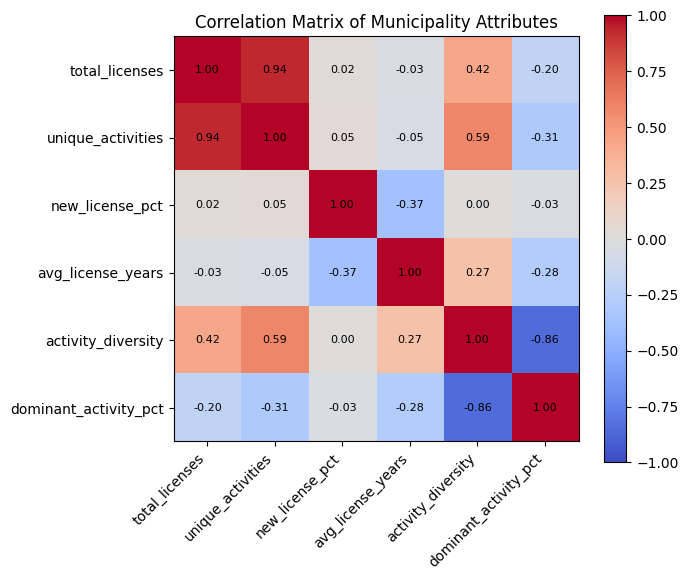

In [16]:
features = [
    "total_licenses", "unique_activities", "new_license_pct",
    "avg_license_years", "activity_diversity", "dominant_activity_pct",
]
corr_matrix = municipality_stats[features].corr()

# Keep each pair once (upper triangle, without the diagonal)
pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack()

print("Highest positive correlation:", pairs.idxmax(), round(pairs.max(), 3))
print("Highest negative correlation:", pairs.idxmin(), round(pairs.min(), 3))

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(features)))
ax.set_xticklabels(features, rotation=45, ha="right")
ax.set_yticks(range(len(features)))
ax.set_yticklabels(features)
for i in range(len(features)):
    for j in range(len(features)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax)
ax.set_title("Correlation Matrix of Municipality Attributes")
plt.tight_layout()
plt.savefig("correlation_matrix.png", dpi=300)
plt.show()

## 4. Clustering data
Each municipality is described by the **proportion of its licences in each ISIC division**.
Divisions with no variation (constant columns) cannot separate municipalities and are removed.

The proportions are already on the same [0, 1] scale, which gives every attribute comparable
weight (Lecture 20). We still test a **standardized** version (z-scores) with K-Means
to check whether extra scaling helps.

In [17]:
X = activity_profiles.loc[:, activity_profiles.nunique() > 1]
X_unscaled = X.to_numpy()
X_scaled = StandardScaler().fit_transform(X)

print("Clustering data shape (municipalities x ISIC divisions):", X.shape)
print("Missing values:", X.isnull().sum().sum())
display(X.head())


def evaluate(X_data, labels, metric="euclidean"):
    """Silhouette (higher = better), Davies-Bouldin (lower = better), smallest cluster size."""
    return {
        "Silhouette": silhouette_score(X_data, labels, metric=metric),
        "Davies-Bouldin": davies_bouldin_score(X_data, labels),
        "Smallest cluster": int(np.bincount(labels).min()),
    }

Clustering data shape (municipalities x ISIC divisions): (376, 75)
Missing values: 0


isic_division,01,03,08,09,10,11,13,14,15,16,...,82,85,86,87,88,90,91,93,95,96
municipality_id,,,,,,,,,,,,,,,,,,,,,
13_114,0.009901,0.0,0.0,0.0,0.004950,0.000000,0.000000,0.044554,0.0,0.004950,...,0.019802,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.004950,0.009901,0.069307
13_13,0.002299,0.0,0.0,0.0,0.010345,0.000000,0.000000,0.022989,0.0,0.004598,...,0.010345,0.005747,0.014943,0.000000,0.002299,0.0,0.0,0.004598,0.010345,0.111494
13_137,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.027027,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.027027,0.000000,0.027027
13_14,0.000000,0.0,0.0,0.0,0.006696,0.000446,0.001339,0.035268,0.0,0.002679,...,0.011161,0.002232,0.005804,0.000446,0.000446,0.0,0.0,0.006250,0.015625,0.079911
13_140,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.090909


## 5. Experiments
### 5.1 K-Means
**Parameters:** k = 2–10, `n_init=20` (20 random starts, best kept), `random_state=42`,
Euclidean distance. Tested on standardized and unscaled proportions.

In [18]:
kmeans_results = []
for scaling, X_data in {"Standardized": X_scaled, "Unscaled proportions": X_unscaled}.items():
    for k in K_RANGE:
        model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
        labels = model.fit_predict(X_data)
        kmeans_results.append({
            "Algorithm": "K-Means", "Setting": scaling, "k": k,
            **evaluate(X_data, labels), "Inertia": model.inertia_,
        })

kmeans_results = pd.DataFrame(kmeans_results)
display(kmeans_results.round(4))

,Algorithm,Setting,k,Silhouette,Davies-Bouldin,Smallest cluster,Inertia
0,K-Means,Standardized,2,0.2256,3.2450,57,26877.9484
1,K-Means,Standardized,3,0.1482,2.8556,3,25898.1852
2,K-Means,Standardized,4,0.0379,3.3415,5,25131.4940
3,K-Means,Standardized,5,0.1505,1.7241,1,24777.6734
4,K-Means,Standardized,6,0.0614,1.9108,1,23812.8000
5,K-Means,Standardized,7,0.0479,2.1921,1,23395.2573
6,K-Means,Standardized,8,0.0328,2.0529,1,22741.6766
7,K-Means,Standardized,9,0.0454,1.8849,1,22268.3027
8,K-Means,Standardized,10,0.0379,1.5594,1,21934.9965
9,K-Means,Unscaled proportions,2,0.3203,1.3615,59,15.2079


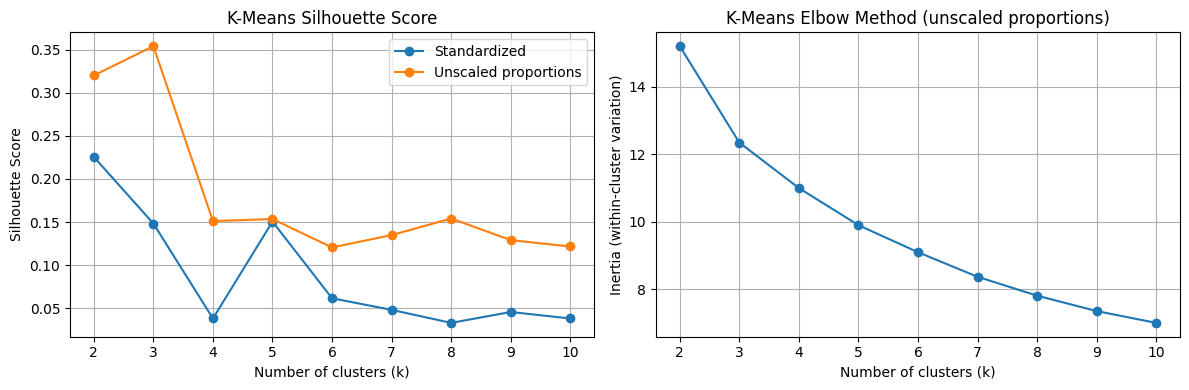

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for scaling, grp in kmeans_results.groupby("Setting"):
    axes[0].plot(grp["k"], grp["Silhouette"], marker="o", label=scaling)
axes[0].set_title("K-Means Silhouette Score")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Silhouette Score")
axes[0].legend()
axes[0].grid(True)

unscaled = kmeans_results[kmeans_results["Setting"] == "Unscaled proportions"]
axes[1].plot(unscaled["k"], unscaled["Inertia"], marker="o")
axes[1].set_title("K-Means Elbow Method (unscaled proportions)")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Inertia (within-cluster variation)")
axes[1].grid(True)

plt.tight_layout()
plt.savefig("kmeans_silhouette_elbow.png", dpi=300)
plt.show()

**Result:** standardization lowers the Silhouette Score at every k. Standardizing gives rare
ISIC divisions the same weight as major sectors, so a handful of municipalities with unusual
activities dominate the distances. **All further experiments use the unscaled proportions.**

### 5.2 K-Medoids (PAM)
**Parameters:** k = 2–10, `method="pam"`, `init="k-medoids++"`, `random_state=42`.
Two distance measures from Lecture 20 are tested: **Euclidean** and **Manhattan**.
The Silhouette Score is calculated with the same distance used for clustering.

In [20]:
def pam(D, k, max_iter=300):
    """PAM (Lecture 22): greedy BUILD of k medoids, then SWAP while total cost decreases."""
    n = D.shape[0]
    medoids = [int(np.argmin(D.sum(axis=1)))]
    while len(medoids) < k:
        nearest = D[:, medoids].min(axis=1)
        gain = np.maximum(nearest[:, None] - D, 0).sum(axis=0)
        gain[medoids] = -1
        medoids.append(int(np.argmax(gain)))
    cost = D[:, medoids].min(axis=1).sum()
    for _ in range(max_iter):
        best_cost, best_swap = cost, None
        for i in range(k):
            others = medoids[:i] + medoids[i + 1:]
            base = D[:, others].min(axis=1) if others else np.full(n, np.inf)
            new_costs = np.minimum(base[:, None], D).sum(axis=0)
            new_costs[medoids] = np.inf
            h = int(np.argmin(new_costs))
            if new_costs[h] < best_cost - 1e-12:
                best_cost, best_swap = new_costs[h], (i, h)
        if best_swap is None:
            break
        medoids[best_swap[0]] = best_swap[1]
        cost = best_cost
    return np.argmin(D[:, medoids], axis=1)


def run_kmedoids(X_data, k, metric):
    if HAVE_SKLEARN_EXTRA:
        model = KMedoids(n_clusters=k, metric=metric, method="pam",
                         init="k-medoids++", random_state=RANDOM_STATE)
        return model.fit_predict(X_data)
    return pam(pairwise_distances(X_data, metric=metric), k)


kmedoids_results = []
for metric in ["euclidean", "manhattan"]:
    for k in K_RANGE:
        labels = run_kmedoids(X_unscaled, k, metric)
        kmedoids_results.append({
            "Algorithm": "K-Medoids", "Setting": metric, "k": k,
            **evaluate(X_unscaled, labels, metric=metric),
        })

kmedoids_results = pd.DataFrame(kmedoids_results)
display(kmedoids_results.round(4))

,Algorithm,Setting,k,Silhouette,Davies-Bouldin,Smallest cluster
0,K-Medoids,euclidean,2,0.2058,1.5981,112
1,K-Medoids,euclidean,3,0.2306,1.2603,7
2,K-Medoids,euclidean,4,0.2105,1.1372,6
3,K-Medoids,euclidean,5,0.1290,1.4661,6
4,K-Medoids,euclidean,6,0.0442,1.5828,6
5,K-Medoids,euclidean,7,0.0481,1.6921,6
6,K-Medoids,euclidean,8,0.0553,1.5323,4
7,K-Medoids,euclidean,9,0.0649,1.3612,1
8,K-Medoids,euclidean,10,0.0788,1.4363,1
9,K-Medoids,manhattan,2,0.1571,2.2277,127


### 5.3 AGNES (agglomerative hierarchical clustering)
**Parameters:** k = 2–10 (the level where the dendrogram is cut), Euclidean distance.
We test the three linkage methods from Lecture 23 (**single**, **complete**, **average**)
plus **Ward** linkage, which merges the pair of clusters that least increases within-cluster variation.

In [21]:
agnes_results = []
for method in ["single", "complete", "average", "ward"]:
    for k in K_RANGE:
        model = AgglomerativeClustering(n_clusters=k, linkage=method, metric="euclidean")
        labels = model.fit_predict(X_unscaled)
        agnes_results.append({
            "Algorithm": "AGNES", "Setting": f"{method} linkage", "k": k,
            **evaluate(X_unscaled, labels),
        })

agnes_results = pd.DataFrame(agnes_results)
display(agnes_results.round(4))

,Algorithm,Setting,k,Silhouette,Davies-Bouldin,Smallest cluster
0,AGNES,single linkage,2,0.7636,0.1604,1
1,AGNES,single linkage,3,0.6649,0.2062,1
2,AGNES,single linkage,4,0.6225,0.2194,1
3,AGNES,single linkage,5,0.5373,0.2516,1
4,AGNES,single linkage,6,0.5599,0.4174,1
5,AGNES,single linkage,7,0.5431,0.4205,1
6,AGNES,single linkage,8,0.5305,0.3838,1
7,AGNES,single linkage,9,0.4479,0.3826,1
8,AGNES,single linkage,10,0.3934,0.3859,1
9,AGNES,complete linkage,2,0.6760,0.9014,8


Single and average linkage reach high Silhouette Scores only by producing **degenerate**
solutions: one huge cluster plus one or a few isolated municipalities (see "Smallest cluster").
This is the chaining effect of single linkage. Such solutions are not useful profiles, so in the
comparison we only accept solutions whose smallest cluster has at least `MIN_CLUSTER_SIZE` municipalities.

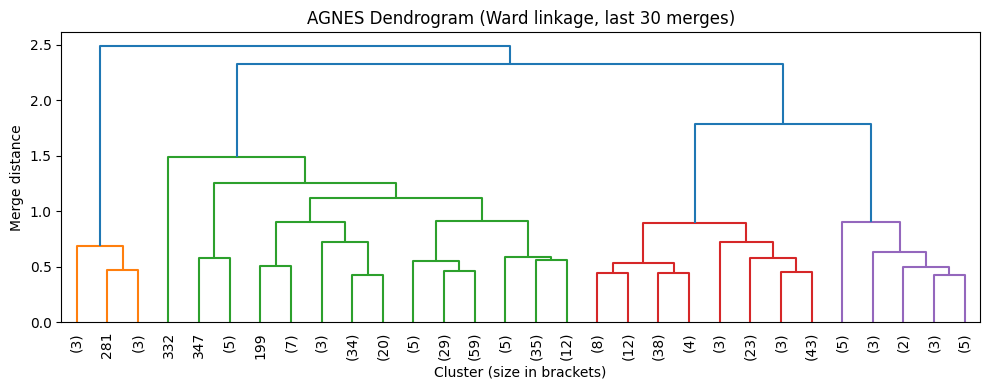

In [22]:
# Dendrogram of the Ward linkage (cut level = number of clusters)
Z = linkage(X_unscaled, method="ward")
plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, no_labels=False)
plt.title("AGNES Dendrogram (Ward linkage, last 30 merges)")
plt.xlabel("Cluster (size in brackets)")
plt.ylabel("Merge distance")
plt.tight_layout()
plt.savefig("agnes_dendrogram.png", dpi=300)
plt.show()

## 6. Evaluation and comparison
### 6.1 Choosing k
We combine all experiments on the unscaled data, drop degenerate solutions, and look at the
best Silhouette Score of each algorithm at each k.

In [23]:
all_results = pd.concat([
    kmeans_results[kmeans_results["Setting"] == "Unscaled proportions"].drop(columns="Inertia"),
    kmedoids_results,
    agnes_results,
], ignore_index=True)

valid = all_results[all_results["Smallest cluster"] >= MIN_CLUSTER_SIZE]
print(f"Solutions kept: {len(valid)} of {len(all_results)}")

best_per_k = valid.pivot_table(index="k", columns="Algorithm", values="Silhouette", aggfunc="max")
display(best_per_k.round(4))

Solutions kept: 22 of 63


Algorithm,AGNES,K-Means,K-Medoids
k,,,
2,0.6760,0.3203,0.2058
3,0.1768,0.3544,0.2306
4,0.1441,0.1511,0.2105
5,NaN,NaN,0.1290
6,NaN,NaN,0.0624
7,NaN,NaN,0.0751
8,NaN,NaN,0.0633
9,NaN,NaN,0.0550
10,NaN,NaN,0.0471


In [24]:
FINAL_K = 3

**k = 3** is chosen for the final model:
- K-Means reaches its highest Silhouette Score and lowest Davies-Bouldin Index at k = 3.
- The Silhouette Score drops sharply from k = 4, and from k = 5 every K-Means solution contains a
  cluster of a single municipality.
- The elbow plot bends at k = 3.

AGNES (complete linkage) scores higher at k = 2, but a two-group split is too coarse to describe
distinct commercial profiles, and at k = 3 complete linkage becomes degenerate.

### 6.2 Algorithm comparison at k = 3
For each algorithm, the best valid setting at the chosen k:

,Algorithm,Setting,k,Silhouette,Davies-Bouldin,Smallest cluster
0,K-Means,Unscaled proportions,3,0.3544,1.0947,7
1,K-Medoids,euclidean,3,0.2306,1.2603,7
2,AGNES,ward linkage,3,0.1768,1.3734,7


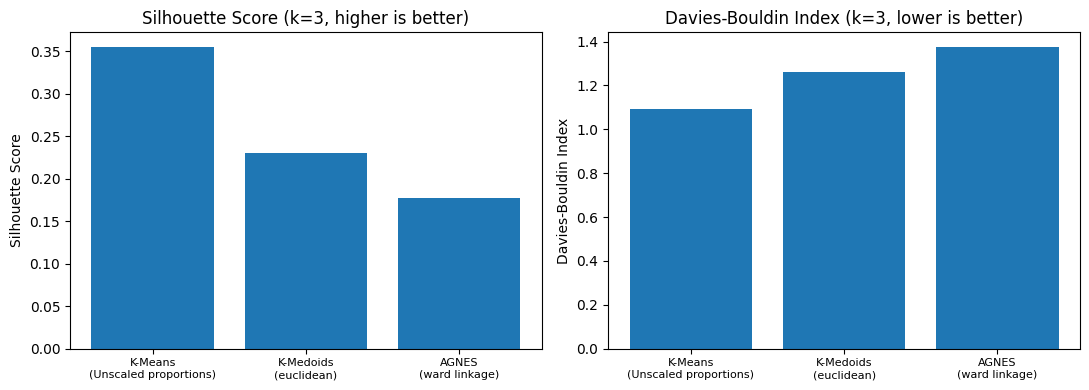

In [25]:
at_k = valid[valid["k"] == FINAL_K]
final_comparison = (
    at_k.sort_values("Silhouette", ascending=False)
    .groupby("Algorithm", sort=False).head(1)
    .reset_index(drop=True)
)
display(final_comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
names = final_comparison["Algorithm"] + "\n(" + final_comparison["Setting"] + ")"
axes[0].bar(names, final_comparison["Silhouette"])
axes[0].set_title(f"Silhouette Score (k={FINAL_K}, higher is better)")
axes[0].set_ylabel("Silhouette Score")
axes[1].bar(names, final_comparison["Davies-Bouldin"])
axes[1].set_title(f"Davies-Bouldin Index (k={FINAL_K}, lower is better)")
axes[1].set_ylabel("Davies-Bouldin Index")
for ax in axes:
    ax.tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.savefig("clustering_comparison.png", dpi=300)
plt.show()

## 7. Final model: K-Means (k = 3, unscaled proportions)

In [26]:
final_model = KMeans(n_clusters=FINAL_K, n_init=20, random_state=RANDOM_STATE)
labels_final = final_model.fit_predict(X_unscaled)

# Attach cluster labels by municipality ID (not by row position)
clusters = pd.Series(labels_final, index=X.index, name="cluster")
cluster_summary = municipality_stats.join(clusters)

print("Final model:", evaluate(X_unscaled, labels_final))
print("\nCluster sizes:")
print(clusters.value_counts().sort_index())

print("\nAverage municipality characteristics per cluster:")
display(cluster_summary.groupby("cluster")[features].mean().round(2))

Final model: {'Silhouette': np.float64(0.35436253567970954), 'Davies-Bouldin': np.float64(1.094747213305603), 'Smallest cluster': 7}

Cluster sizes:
cluster
0     57
1      7
2    312
Name: count, dtype: int64

Average municipality characteristics per cluster:


,total_licenses,unique_activities,new_license_pct,avg_license_years,activity_diversity,dominant_activity_pct
cluster,,,,,,
0,60.46,25.68,31.63,5.00,1.31,57.75
1,28.29,9.43,25.87,4.01,0.75,73.77
2,349.48,109.19,33.47,5.28,2.12,35.34


In [27]:
# Most prominent ISIC divisions in each cluster (mean share of licences)
mean_profiles = X.groupby(clusters).mean()

for c in mean_profiles.index:
    top = mean_profiles.loc[c].sort_values(ascending=False).head(5)
    print(f"\nCluster {c} – top 5 ISIC divisions")
    for div, share in top.items():
        print(f"  {div} {ISIC_NAMES.get(div, ''):35s} {share:6.1%}")


Cluster 0 – top 5 ISIC divisions
  47 Retail trade                         57.8%
  56 Food & beverage services              8.8%
  96 Other personal services               7.3%
  45 Motor vehicle trade & repair          5.9%
  46 Wholesale trade                       3.2%

Cluster 1 – top 5 ISIC divisions
  56 Food & beverage services             73.8%
  47 Retail trade                          7.0%
  96 Other personal services               5.4%
  55 Accommodation                         5.0%
  46 Wholesale trade                       2.6%

Cluster 2 – top 5 ISIC divisions
  47 Retail trade                         34.0%
  56 Food & beverage services             16.3%
  45 Motor vehicle trade & repair         10.6%
  96 Other personal services               8.1%
  46 Wholesale trade                       3.4%


In [28]:
# Largest municipalities in each cluster
for c in sorted(clusters.unique()):
    members = cluster_summary[cluster_summary["cluster"] == c]
    print(f"\nCluster {c}: {len(members)} municipalities, e.g.")
    display(members.nlargest(5, "total_licenses")[["amanah", "municipality", "total_licenses"]])


Cluster 0: 57 municipalities, e.g.


,amanah,municipality,total_licenses
municipality_id,,,
21_416,أمانة محافظة جدة,بلدية البلد,889
178_642,أمانة العاصمة المقدسة,المنطقة المركزية,460
213_214,أمانة المدينة المنورة,بلدية الحرم,288
88_571,أمانة منطقة تبوك,بلدية وسط المدينة,259
21_131,أمانة محافظة جدة,بلدية القنفذة,204



Cluster 1: 7 municipalities, e.g.


,amanah,municipality,total_licenses
municipality_id,,,
321_321,أمانة منطقة الرياض,أمانة منطقة الرياض,91
300_315,أمانة محافظة الطائف,بلدية الهدا الفرعية,46
178_192,أمانة العاصمة المقدسة,بلدية المشاعر المقدسة,33
193_237,أمانة منطقة الاحساء,بلدية البطحاء,13
13_23,أمانة منطقة عسير,فرع السوده,11



Cluster 2: 312 municipalities, e.g.


,amanah,municipality,total_licenses
municipality_id,,,
321_355,أمانة منطقة الرياض,بلدية الروضة,3794
21_421,أمانة محافظة جدة,بلدية المطار,2935
8_3,أمانة المنطقة الشرقية,بلدية محافظة الخبر,2800
321_326,أمانة منطقة الرياض,بلدية البطحاء,2708
321_351,أمانة منطقة الرياض,بلدية العليا,2527


**Interpretation of the clusters**
- **Mixed commercial municipalities** (the large cluster): the most licences and activity types,
  the highest diversity, with retail around a third of licences and a broad mix of food services,
  vehicle trade and personal services. Most city districts belong here.
- **Retail-dominated municipalities**: retail trade makes up more than half of all licences.
  This includes historic market centres such as Al-Balad in Jeddah, the Central Area of Makkah
  and the Haram area of Madinah.
- **Food & hospitality municipalities** (a small cluster): food and beverage services dominate,
  with accommodation also present. These are tourism and pilgrimage areas such as Al-Hada (Taif)
  and the Holy Sites (Al-Masha'er) in Makkah.

(Cluster numbers can change between environments; match them using the top ISIC divisions above.)

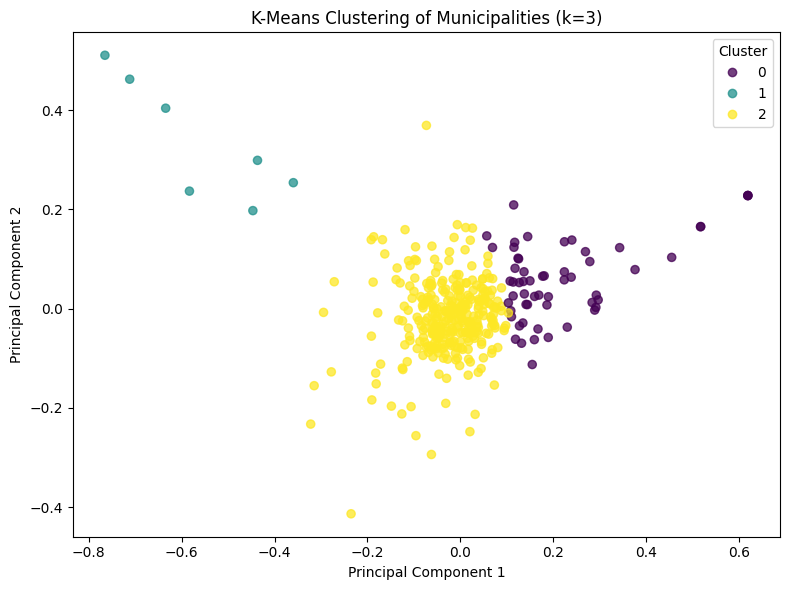

Variance explained by the first two components: 61.14 %


In [29]:
# Visualize the clusters in 2D using PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_unscaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_final, cmap="viridis", alpha=0.75, s=35)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(f"K-Means Clustering of Municipalities (k={FINAL_K})")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.tight_layout()
plt.savefig("kmeans_clusters_pca.png", dpi=300)
plt.show()

print("Variance explained by the first two components:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

In [30]:
# Save the cluster assignment of every municipality
cluster_summary.to_csv("municipality_clusters.csv", encoding="utf-8-sig")
print("Saved municipality_clusters.csv")

Saved municipality_clusters.csv
